In [238]:
import numpy as np
import models as ml
import pandas as pd
import matplotlib.pyplot as plt

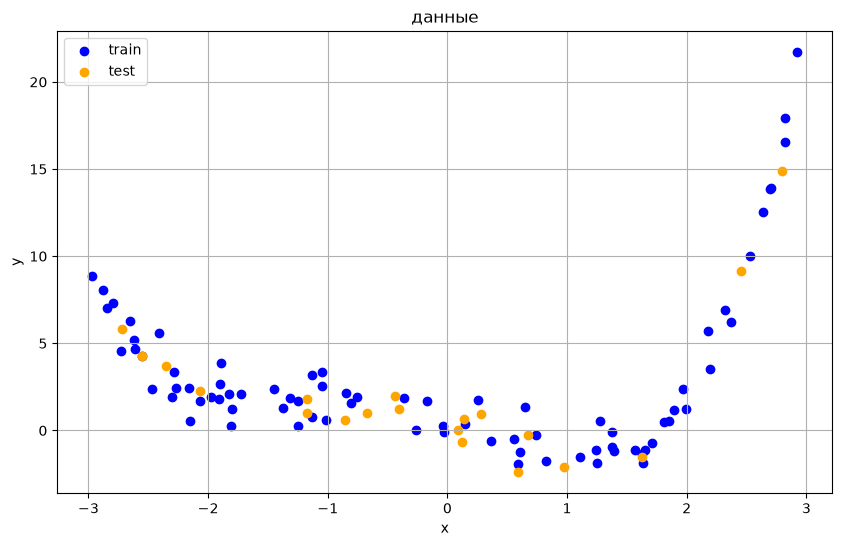

In [239]:
np.random.seed(42)

x = np.random.uniform(-3, 3, size=(100, 1))

y = (0.3 * x**4 + 0.5 * x**3 - x**2 - 2 * x + 1 + np.random.normal(0, 1, size=(100, 1))).ravel()

m = int(len(x) * 0.8)
idx = np.random.permutation(len(x))
train_idx, test_idx = idx[:m], idx[m:]

x_train, y_train = x[train_idx], y[train_idx]
x_test, y_test = x[test_idx], y[test_idx]

plt.figure(figsize=(10, 6))
plt.scatter(x_train, y_train, color='blue', label='train')
plt.scatter(x_test, y_test, color='orange', label='test')
plt.title('данные')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True)
plt.show()


линейная модель: R2  = -0.012
полиномиальная модель, degree=6: R2  = 0.849


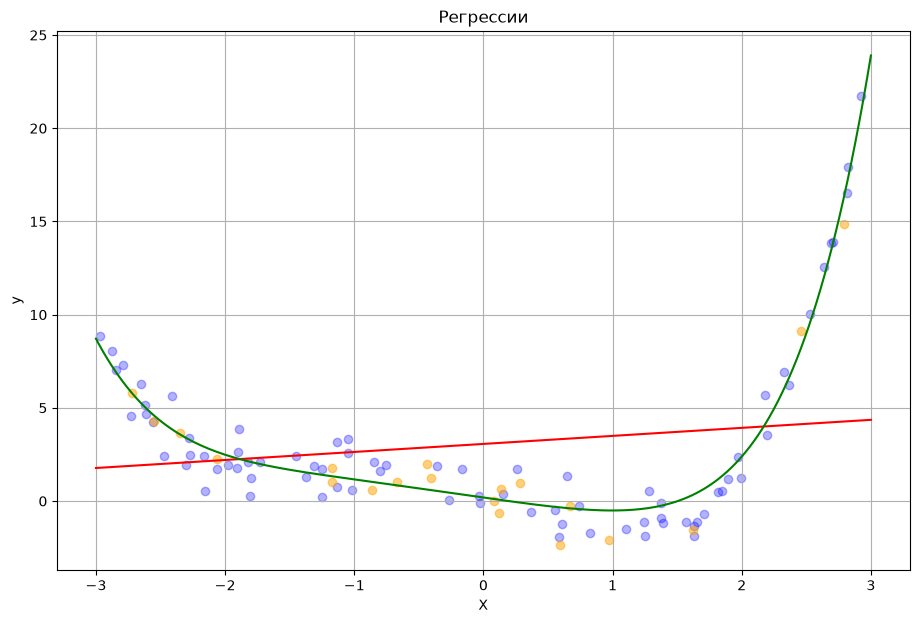

In [240]:
lin_model = ml.LinearRegression().fit(x_train, y_train)
y_pred_lin = lin_model.predict(x_test)
r2_lin = ml.r2_score(y_test, y_pred_lin)

poly_model = ml.PolynomialRegression(lr = 0.001, n_iters=10000)
poly_model.fit(x_train, y_train)

y_pred_poly = poly_model.predict(x_test)
r2_pol = ml.r2_score(y_test, y_pred_poly)

print('=' * 60)
print(f'линейная модель: R2  = {r2_lin:.3f}')
print(f'полиномиальная модель, degree={poly_model.degree}: R2  = {r2_pol:.3f}')
print('=' * 60)

x_grid = np.linspace(-3, 3, 200).reshape(-1, 1)

plt.figure(figsize=(11, 7))
plt.scatter(x_train, y_train, color='blue', alpha=0.3)
plt.scatter(x_test, y_test, color='orange', alpha=0.5)
plt.plot(x_grid, lin_model.predict(x_grid), color='red')
plt.plot(x_grid, poly_model.predict(x_grid), color='green')
plt.title('Регрессии')
plt.xlabel('X')
plt.ylabel('y')
plt.grid(True)
plt.show()

оптимальная степень полинома: 6, R2 = 0.928


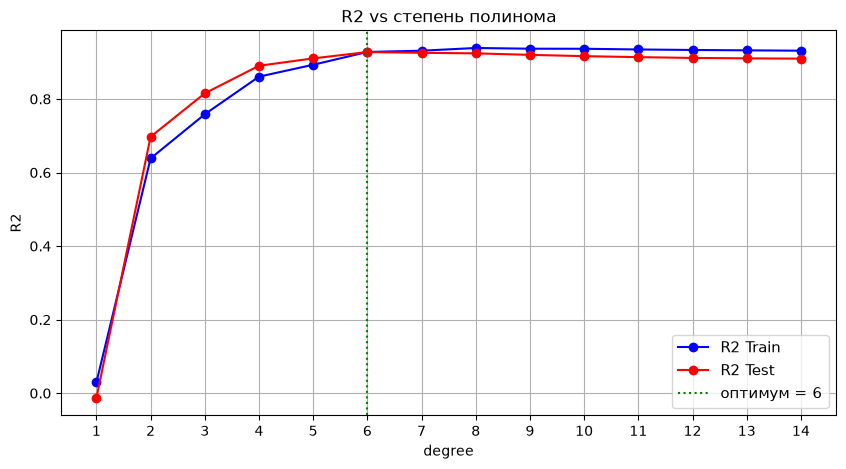

In [241]:
r2_train_list = []
r2_test_list = []
degrees = range(1,15)

for d in degrees:
    poly = ml.PolynomialFeatures(degree=d)
    x_train_poly = poly.transform(x_train)
    x_test_poly = poly.transform(x_test)

    mean = np.mean(x_train_poly, axis=0)
    std = np.std(x_train_poly, axis=0)
    x_train_poly = (x_train_poly - mean) / std
    x_test_poly = (x_test_poly - mean) / std

    model = ml.LinearRegression(lr=0.001, regularization='L2', n_iters=10000).fit(x_train_poly, y_train)

    r2_train = ml.r2_score(y_train, model.predict(x_train_poly))
    r2_test = ml.r2_score(y_test, model.predict(x_test_poly))

    r2_train_list.append(r2_train)
    r2_test_list.append(r2_test)

best_degree = degrees[np.argmax(r2_test_list)]
print(f'оптимальная степень полинома: {best_degree}, R2 = {max(r2_test_list):.3f}')

plt.figure(figsize=(10, 5))
plt.plot(degrees, r2_train_list, marker='o', color='blue', label='R2 Train')
plt.plot(degrees, r2_test_list, marker='o', color='red', label='R2 Test')

plt.axvline(best_degree, color='green', linestyle=':', label=f'оптимум = {best_degree}')
plt.title('R2 vs степень полинома')
plt.xlabel('degree')
plt.ylabel('R2')
plt.xticks(degrees)
plt.legend(fontsize=11)
plt.grid(True)
plt.show()

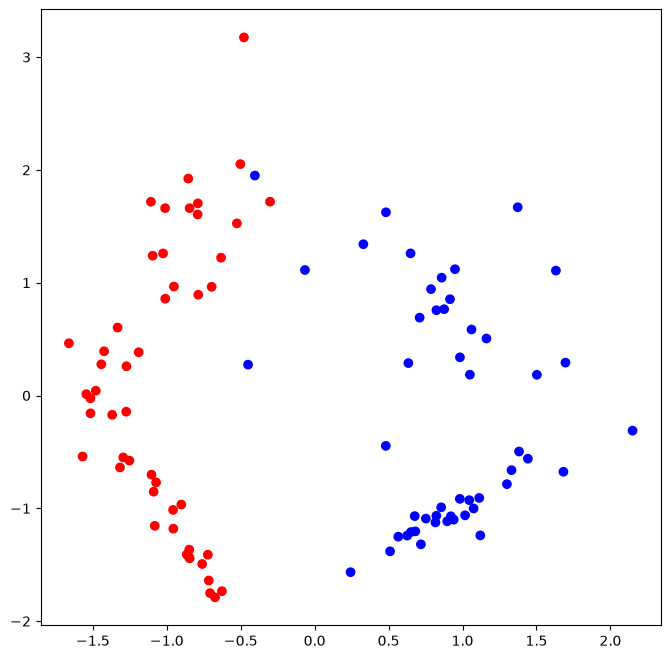

In [242]:
from sklearn import datasets
from matplotlib.colors import ListedColormap

X, y = datasets.make_classification(n_samples=100, n_features=2, n_informative=2, n_redundant=0, n_classes=2, random_state=1)

colors = ListedColormap(['red', 'blue'])
plt.figure(figsize=(8, 8))
plt.scatter([x[0] for x in X], [x[1] for x in X], c=y, cmap=colors)

plt.show()

accuracy = 1.00
presicion = 1.00
recall = 1.00
F1 = 1.00
[2.01754557 0.07374667] 0.014375387339502922


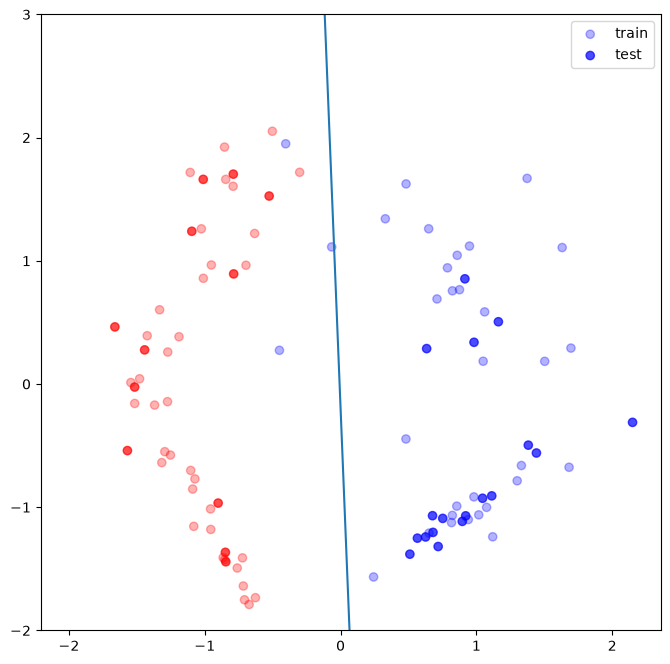

In [243]:
np.random.seed(42)
m = int(X.shape[0] * 0.7)
shuffle_index = np.random.permutation(X.shape[0])
X_shuffled, y_shuffled = X[shuffle_index], y[shuffle_index]
train_idx, test_idx = shuffle_index[:m], shuffle_index[m:]
X_train, y_train = X[train_idx], y[train_idx]
X_test, y_test = X[test_idx], y[test_idx]

model = ml.LogisticRegression().fit(X_train, y_train)

print('='*60)
print(f'accuracy = {ml.accuracy(y_test, model.predict(X_test)):.2f}')
print(f'presicion = {ml.precision(y_test, model.predict(X_test)):.2f}')
print(f'recall = {ml.recall(y_test, model.predict(X_test)):.2f}')
print(f'F1 = {ml.f1_score(y_test, model.predict(X_test)):.2f}')
print('='*60)

plt.figure(figsize=(8, 8))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=colors, alpha=0.3, label='train')
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap=colors, alpha=0.7, label='test')
grid = np.linspace(-2, 2, 200)
plt.ylim(-2, 3)
plt.plot(grid, -(model.coef_[0]*grid + model.intercept_) / model.coef_[1])
print(model.coef_ , model.intercept_)
plt.legend()
plt.show()

accuracy = 1.00
precision = 1.00
recall = 1.00
F1 = 1.00


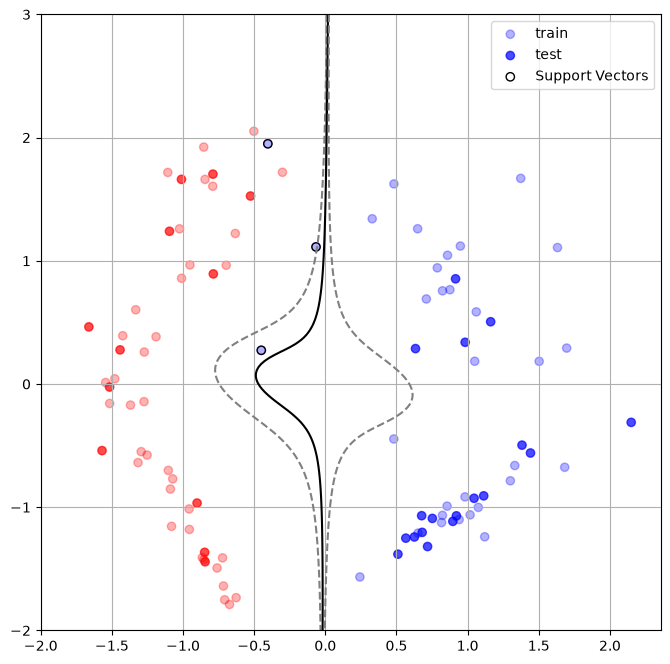

In [244]:
y_train_svc = np.where(y_train == 0, -1, 1)
y_test_svc = np.where(y_test == 0, -1, 1)
model_svc = ml.SVC_binary(kernel='poly', C=1.0, lr=0.01, n_iters=1000)
model_svc.fit(X_train, y_train_svc)

preds_raw = model_svc.predict(X_test)
preds = np.where(preds_raw >= 0, 1, 0)

print('=' * 60)
print(f'accuracy = {ml.accuracy(y_test, preds):.2f}')
print(f'precision = {ml.precision(y_test, preds):.2f}')
print(f'recall = {ml.recall(y_test, preds):.2f}')
print(f'F1 = {ml.f1_score(y_test, preds):.2f}')
print('=' * 60)

w = model_svc.X_train_.T @ model_svc.coef_
b = model_svc.intercept_

plt.figure(figsize=(8, 8))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=colors, alpha=0.3, label='train')
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap=colors, alpha=0.7, label='test')

sv = model_svc.support_vectors_
plt.scatter(sv[:, 0], sv[:, 1], facecolors='none', edgecolors='black', label='Support Vectors')

xx, yy = np.meshgrid(np.linspace(-2, 2, 200), np.linspace(-2, 3, 200))
grid = np.c_[xx.ravel(), yy.ravel()]
Z = model_svc.decision_function(grid).reshape(xx.shape)

contour = plt.contour(
    xx, yy, Z, levels=[-1.0, 0.0, 1.0], colors=['gray', 'black', 'gray'], linestyles=['--', '-', '--'])
plt.ylim(-2, 3)
plt.legend()
plt.grid(True)
plt.show()

SVR: R2  = 0.940


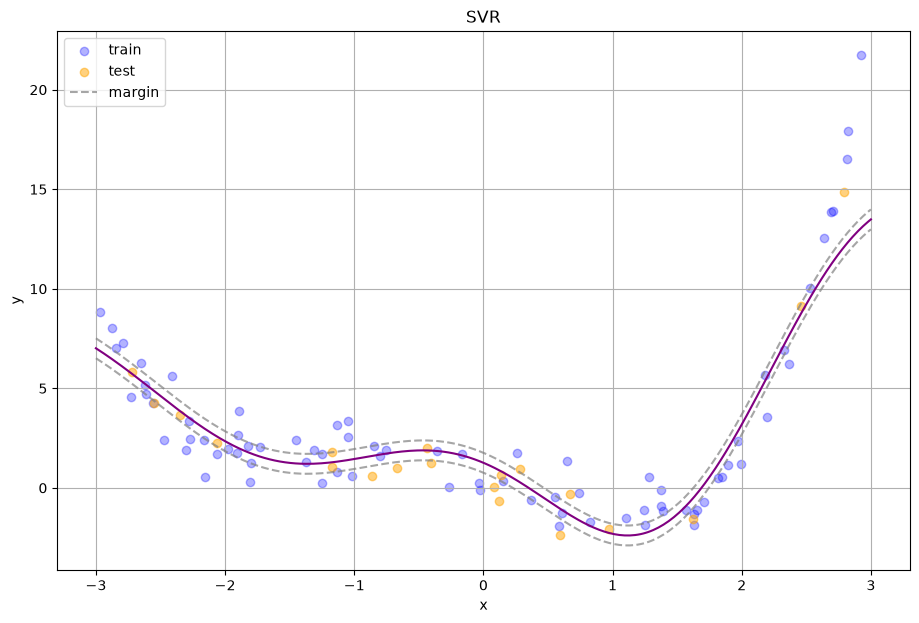

In [245]:
np.random.seed(42)

x = np.random.uniform(-3, 3, size=(100, 1))
y = (0.3 * x**4 + 0.5 * x**3 - x**2 - 2 * x + 1 + np.random.normal(0, 1, size=(100, 1))).ravel()
m = int(len(x) * 0.8)
idx = np.random.permutation(len(x))
train_idx, test_idx = idx[:m], idx[m:]

x_train, y_train = x[train_idx], y[train_idx]
x_test, y_test = x[test_idx], y[test_idx]

svr = ml.SVR(kernel='rbf', gamma=0.5, C=100.0, epsilon=0.5, lr=0.001, n_iters=3000, degree=4)
svr.fit(x_train, y_train)

y_pred_svr = svr.predict(x_test)
r2_svr = ml.r2_score(y_test, y_pred_svr)
print('=' * 60)
print(f'SVR: R2  = {r2_svr:.3f}')
print('=' * 60)

x_grid = np.linspace(-3, 3, 300).reshape(-1, 1)
y_grid = svr.predict(x_grid)

plt.figure(figsize=(11, 7))
plt.scatter(x_train, y_train, color='blue', alpha=0.3, label='train')
plt.scatter(x_test, y_test, color='orange', alpha=0.5, label='test')

plt.plot(x_grid, y_grid, color='purple')
plt.plot(x_grid, y_grid + svr.epsilon, '--', color='gray', alpha=0.7, label = 'margin')
plt.plot(x_grid, y_grid - svr.epsilon, '--', color='gray', alpha=0.7)

plt.title('SVR')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True)
plt.show()

accuracy ovr: 0.85
accuracy ovo: 0.87


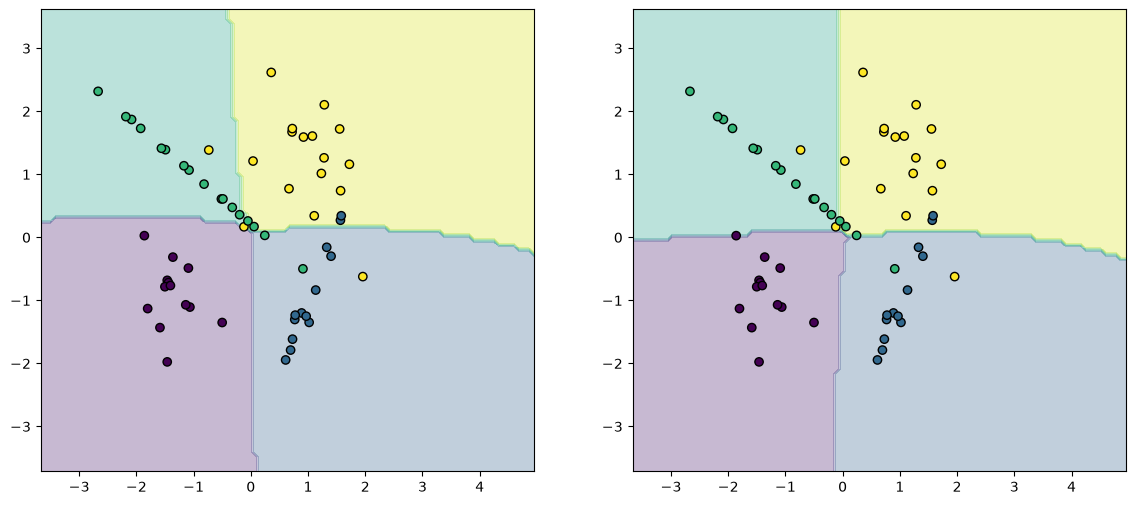

In [246]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_classification
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

X, y = make_classification(n_samples=300, n_features=2, n_informative=2, n_redundant=0, n_classes=4, n_clusters_per_class=1, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model_ovr = ml.SVC(decision_function_shape='ovr').fit(X_train, y_train)
model_ovo = ml.SVC(decision_function_shape='ovo').fit(X_train, y_train)

acc_ovr = accuracy_score(y_test, model_ovr.predict(X_test))
acc_ovo = accuracy_score(y_test, model_ovo.predict(X_test))

print('=' * 45)
print(f'accuracy ovr: {acc_ovr:.2f}')
print(f'accuracy ovo: {acc_ovo:.2f}')
print('=' * 45)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

xx, yy = np.meshgrid(
    np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 100),
    np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 100),)
grid = np.c_[xx.ravel(), yy.ravel()]

Z_ovr = model_ovr.predict(grid).reshape(xx.shape)
axes[0].contourf(xx, yy, Z_ovr, alpha=0.3)
axes[0].scatter(X_test[:, 0], X_test[:, 1], c=y_test, edgecolors="k")

Z_ovo = model_ovo.predict(grid).reshape(xx.shape)
axes[1].contourf(xx, yy, Z_ovo, alpha=0.3)
axes[1].scatter(X_test[:, 0], X_test[:, 1], c=y_test, edgecolors="k")


plt.show()